# Multivariate Regression

## Use case: Digital Skills Pay Estimator for African Youth

My mission is to equip youth in underserved African communities with skills and pathways they need to become self-reliant. Majority of young Africans learning to code may not always know the value of their skills or which path (more experience, a degree, online courses, remote work) leads to higher pay. This model forecasts the dollar amount of global annual pay (USD) a young African developer, aged 18-34, can expect to make, given their country of origin and education level, coding and work experience, work role and location, size of organization, employment type and online-education participation.

**Who is it for and how is it used:**

- Developers in the early stages of their careers to consider if an offer is fair and what change (another role, change of location, more expertise) is likely to increase pay.
- Youth skills programmes and boot camps to inform learners about how much to expect to earn and which options pay.

## 1. Data loading and vetting

In [1]:
import numpy as np
import pandas as pd

# African countries, spelled exactly as they appear in the survey's Country column
AFRICA = {
    "Algeria", "Angola", "Benin", "Botswana", "Burkina Faso", "Burundi", "Cameroon",
    "Cape Verde", "Central African Republic", "Chad", "Congo, Republic of the...",
    "Côte d'Ivoire", "Democratic Republic of the Congo", "Djibouti", "Egypt",
    "Equatorial Guinea", "Ethiopia", "Gabon", "Gambia", "Ghana", "Guinea",
    "Guinea-Bissau", "Kenya", "Lesotho", "Liberia", "Libyan Arab Jamahiriya",
    "Madagascar", "Malawi", "Mali", "Mauritania", "Mauritius", "Morocco", "Mozambique",
    "Namibia", "Niger", "Nigeria", "Rwanda", "Senegal", "Sierra Leone", "Somalia",
    "South Africa", "Sudan", "Swaziland", "Togo", "Tunisia", "Uganda",
    "United Republic of Tanzania", "Zambia", "Zimbabwe",
}
YEARS = (2023, 2024, 2025, 2026)
YOUTH = ["18-24 years old", "25-34 years old"]   # AU youth definition: up to 35

frames = {}
for year in YEARS:
    d = pd.read_csv(f"stackoverflow_{year}.csv", low_memory=False)
    d["SurveyYear"] = year
    africa_pay = d[d["Country"].isin(AFRICA) & d["ConvertedCompYearly"].notna()]
    frames[year] = africa_pay
    print(f"{year}: all={len(d):>6} | African={d['Country'].isin(AFRICA).sum():>5} "
          f"| African with pay={len(africa_pay):>4} | columns={d.shape[1]}")

df = pd.concat(frames.values(), ignore_index=True)
pay = df["ConvertedCompYearly"]

print("\nCombined African rows with pay:", len(df))
print("Of which youth (18–34):", df["Age"].isin(YOUTH).sum())
print("\nPay (USD/year):\n", pay.describe(percentiles=[.01, .05, .5, .95, .99]).round(0))
print("\nTop countries:\n", df["Country"].value_counts().head(8))

# Columns renamed between years
for old, new in [("EdLevel", "Education"), ("RemoteWork", "WorkSetting"), ("DevType", "Role")]:
    print(f"\n{old}/{new} present per year:",
          {y: (old in f.columns, new in f.columns) for y, f in frames.items()})

2023: all= 89184 | African= 2534 | African with pay= 926 | columns=85
2024: all= 65437 | African= 1837 | African with pay= 555 | columns=115
2025: all= 49191 | African= 1178 | African with pay= 645 | columns=173
2026: all= 30903 | African=  717 | African with pay= 383 | columns=213

Combined African rows with pay: 2509
Of which youth (18–34): 1751

Pay (USD/year):
 count        2509.0
mean       109490.0
std       1783547.0
min             1.0
1%              6.0
5%            133.0
50%         13598.0
95%        103743.0
99%        270476.0
max      73607918.0
Name: ConvertedCompYearly, dtype: float64

Top countries:
 Country
South Africa    789
Nigeria         425
Egypt           233
Kenya           231
Morocco         108
Tunisia          89
Ghana            79
Ethiopia         73
Name: count, dtype: int64

EdLevel/Education present per year: {2023: (True, False), 2024: (True, False), 2025: (True, False), 2026: (False, True)}

RemoteWork/WorkSetting present per year: {2023: (True, F

No single survey year has 1,000 African respondents with pay (926 / 555 / 645 / 383), so I combine 2023–2026 (2,509 rows). Pay ranges from USD 1 to USD 73.6M against a median of about USD 13.6k, so implausible values are removed in the next step.

## 2. Data cleaning and harmonisation

In [2]:
# Columns that were renamed between survey years given one common name
RENAME = {"EdLevel": "Education", "RemoteWork": "WorkSetting", "DevType": "Role"}


def years_to_num(s):
    """'Less than 1 year' → 0.5, 'More than 50 years' → 51, numbers → float."""
    return pd.to_numeric(
        s.replace({"Less than 1 year": 0.5, "More than 50 years": 51}), errors="coerce"
    )


def education(x):
    x = str(x).lower()
    if "primary" in x or "secondary" in x:  return "Secondary or less"
    if "without earning" in x:              return "Some university, no degree"
    if "associate" in x:                    return "Associate degree"
    if "bachelor" in x:                     return "Bachelor's degree"
    if "master" in x:                       return "Master's degree"
    if "professional" in x:                 return "Doctorate or professional degree"
    return np.nan                          


def work_mode(x):
    x = str(x).lower()
    if x.startswith("remote"):    return "Remote"
    if x.startswith("in-person"): return "In-person"
    if x.startswith("hybrid") or x.startswith("your choice"): return "Hybrid"
    return np.nan


def org_size(x):
    x = str(x)
    if x.startswith("Just me"):                                  return "Freelancer (just me)"
    if x.startswith(("2 to 9", "10 to 19", "Less than 20")):    return "Under 20"
    if x.startswith("20 to 99"):                                 return "20-99"
    if x.startswith("100 to 499"):                               return "100-499"
    if x.startswith(("500 to 999", "1,000 to 4,999")):          return "500-4,999"
    if x.startswith(("5,000 to 9,999", "10,000 or more")):      return "5,000+"
    return np.nan                                               


def employment(x):
    x = str(x)
    employed, freelance = "Employed" in x, "Independent contractor" in x
    if employed and freelance: return "Employed and freelancing"
    if freelance:              return "Freelancer or self-employed"
    if employed:               return "Employed"
    return np.nan                                                


def role_group(x):
    x = str(x).lower()
    if "full-stack" in x:  return "Full-stack developer"
    if "back-end" in x:    return "Back-end developer"
    if "front-end" in x:   return "Front-end developer"
    if "mobile" in x:      return "Mobile developer"
    if any(k in x for k in ("data", "machine learning", "ai/ml")): return "Data or AI"
    if x == "nan":         return np.nan
    return "Other tech role"


frames = []
for year in YEARS:
    d = pd.read_csv(f"stackoverflow_{year}.csv", low_memory=False).rename(columns=RENAME)
    d = d[d["Country"].isin(AFRICA) & d["ConvertedCompYearly"].notna()].copy()

    # Learning pathway: 2023–2025 use LearnCode; 2026 moved the answers to LearnCodeHow
    learn = d["LearnCodeHow"] if year == 2026 else d["LearnCode"]
    d["OnlineCourses"] = learn.fillna("").str.contains("online course", case=False).astype(int)

    d["WorkExp"] = years_to_num(d["WorkExp"])
    if "YearsCodePro" in d:
        d["WorkExp"] = d["WorkExp"].fillna(years_to_num(d["YearsCodePro"]))

    d["SurveyYear"] = year
    frames.append(d)

raw = pd.concat(frames, ignore_index=True)

clean = pd.DataFrame({
    "Country":        raw["Country"],
    "AgeGroup":       raw["Age"],
    "Education":      raw["Education"].map(education),
    "YearsCode":      years_to_num(raw["YearsCode"]),
    "WorkExp":        raw["WorkExp"],
    "WorkMode":       raw["WorkSetting"].map(work_mode),
    "OrgSize":        raw["OrgSize"].map(org_size),
    "EmploymentType": raw["Employment"].map(employment),
    "RoleGroup":      raw["Role"].map(role_group),
    "OnlineCourses":  raw["OnlineCourses"],
    "SurveyYear":     raw["SurveyYear"],
    "AnnualPayUSD":   raw["ConvertedCompYearly"],
})

clean = clean[clean["AgeGroup"].isin(["18-24 years old", "25-34 years old"])]
clean["AgeGroup"] = clean["AgeGroup"].str.replace(" years old", "", regex=False)

# Remove implausible pay (under $50/month or over $300k/year)
clean = clean[clean["AnnualPayUSD"].between(600, 300_000)]

before = len(clean)
clean = clean.dropna().reset_index(drop=True)

# Remove experience that is impossible for the age group (e.g. 51 years of coding at age 24)
max_years = {"18-24": (18, 8), "25-34": (28, 18)}   
limits = clean["AgeGroup"].map(max_years)
plausible = (clean["YearsCode"] <= limits.str[0]) & (clean["WorkExp"] <= limits.str[1])
print("Rows removed for impossible experience:", (~plausible).sum())
clean = clean[plausible].reset_index(drop=True)

# Countries with few respondents (<30) are grouped into "Other African country"
counts = clean["Country"].value_counts()
clean["Country"] = clean["Country"].where(clean["Country"].map(counts) >= 30, "Other African country")
clean[["YearsCode", "WorkExp"]] = clean[["YearsCode", "WorkExp"]].astype(float)

print(f"Rows after youth + pay filters: {before} → after removing missing and implausible rows: {len(clean)}")
print("Features:", clean.shape[1] - 1, "| Target: AnnualPayUSD")
print(clean.dtypes, "\n")
for c in ["Country", "Education", "WorkMode", "OrgSize", "EmploymentType", "RoleGroup"]:
    print(c, clean[c].value_counts().to_dict(), "\n")

clean.to_csv("data.csv", index=False)
print("Saved data.csv:", clean.shape)
clean.head()

Rows removed for impossible experience: 8
Rows after youth + pay filters: 1518 → after removing missing and implausible rows: 1355
Features: 11 | Target: AnnualPayUSD
Country               str
AgeGroup              str
Education             str
YearsCode         float64
WorkExp           float64
WorkMode              str
OrgSize               str
EmploymentType        str
RoleGroup             str
OnlineCourses       int64
SurveyYear          int64
AnnualPayUSD      float64
dtype: object 

Country {'South Africa': 332, 'Other African country': 244, 'Nigeria': 223, 'Egypt': 147, 'Kenya': 144, 'Morocco': 80, 'Tunisia': 58, 'Ghana': 52, 'Ethiopia': 40, 'Algeria': 35} 

Education {"Bachelor's degree": 831, "Master's degree": 203, 'Some university, no degree': 198, 'Secondary or less': 76, 'Associate degree': 34, 'Doctorate or professional degree': 13} 

WorkMode {'Remote': 536, 'Hybrid': 518, 'In-person': 301} 

OrgSize {'Under 20': 486, '20-99': 346, '100-499': 182, '500-4,999': 154, 'Fre

,Country,AgeGroup,Education,YearsCode,WorkExp,WorkMode,OrgSize,EmploymentType,RoleGroup,OnlineCourses,SurveyYear,AnnualPayUSD
0,Nigeria,25-34,Bachelor's degree,8.0,6.0,Remote,20-99,Employed and freelancing,Full-stack developer,1,2023,120000.0
1,Egypt,25-34,Master's degree,5.0,5.0,Hybrid,"500-4,999",Employed,Other tech role,1,2023,7000.0
2,Morocco,25-34,Bachelor's degree,5.0,3.0,Hybrid,Freelancer (just me),Employed,Full-stack developer,0,2023,12851.0
3,Egypt,18-24,Bachelor's degree,4.0,2.0,Remote,Under 20,Employed,Back-end developer,1,2023,3247.0
4,Other African country,18-24,Bachelor's degree,4.0,1.0,In-person,Under 20,Employed,Full-stack developer,1,2023,5715.0


I added together the survey results for each year, renamed the columns for uniformity, and retained the Africans who were age 18–34 and earning between USD 600 and USD 300,000. I grouped the text answers, added an online-course factor, converted experience to numbers, filling missing work experience with years of professional coding, and omitted rows with missing values or experience that was not possible for their age. There were 1355 rows in data.csv after grouping African countries with less than 30 responses as ‘Other African country'.

## 3. Exploratory data analysis

### 3.1. Load the cleaned data

From here the notebook runs from data.csv alone.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")
df["LogPay"] = np.log1p(df["AnnualPayUSD"])   # log(1 + pay), is used to reduce skew
print(df.shape)
df.describe().round(2)

(1355, 13)


,YearsCode,WorkExp,OnlineCourses,SurveyYear,AnnualPayUSD,LogPay
count,1355.00,1355.00,1355.00,1355.00,1355.00,1355.00
mean,7.99,4.91,0.65,2024.00,21777.28,9.28
std,3.91,3.09,0.48,1.04,26865.88,1.29
min,1.00,0.00,0.00,2023.00,600.00,6.40
25%,5.00,3.00,0.00,2023.00,4254.00,8.36
50%,7.00,4.00,1.00,2024.00,12000.00,9.39
75%,10.00,7.00,1.00,2025.00,29057.00,10.28
max,25.00,16.00,1.00,2026.00,234883.00,12.37


### 3.2. Distribution of the target

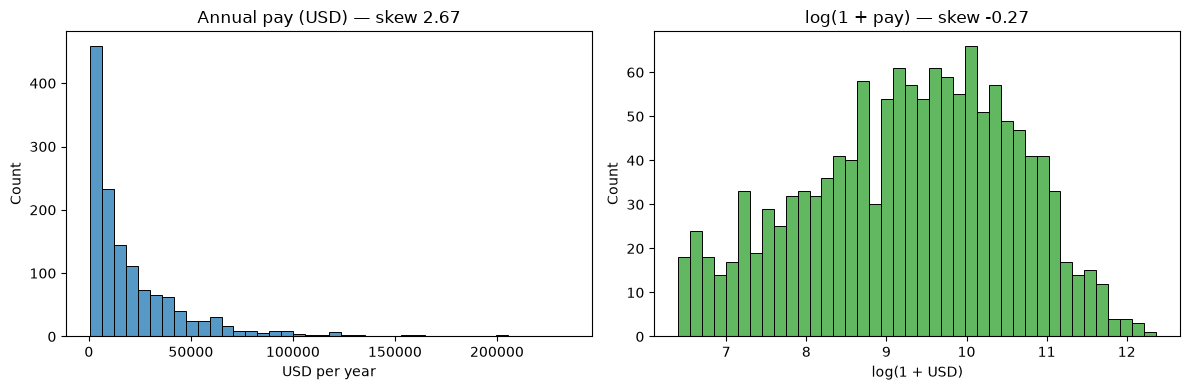

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["AnnualPayUSD"], bins=40, ax=axes[0])
axes[0].set(title=f"Annual pay (USD) — skew {df['AnnualPayUSD'].skew():.2f}", xlabel="USD per year")
sns.histplot(df["LogPay"], bins=40, ax=axes[1], color="tab:green")
axes[1].set(title=f"log(1 + pay) — skew {df['LogPay'].skew():.2f}", xlabel="log(1 + USD)")
plt.tight_layout()
plt.show()

What it shows: Annual pay is highly right skewed (skew 2.67). The majority of responses are below USD 30k (median USD 12k), but there is a long tail extending to around USD 235k. Post-log scale it becomes approximately symmetrical (skew 0.27).

Decision: I train all the models on log(1+pay) otherwise the squared-error loss would be dominated by the few folks earning tons. The API converts back from log(1+pay) to USD using expm1.

### 3.3. Correlation heatmap

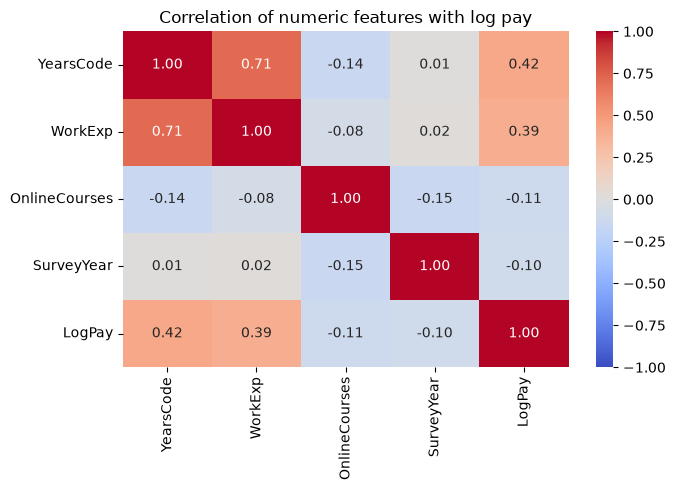

In [5]:
num_cols = ["YearsCode", "WorkExp", "OnlineCourses", "SurveyYear", "LogPay"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of numeric features with log pay")
plt.tight_layout()
plt.show()

What it shows: Years Code (0.42) and Work Exp (0.39) are most strongly numeric predictors of log pay. They're correlated with each other (0.71) but not near-duplicates. Online Courses (0.11) and Survey Year (0.10) are weak.

Decision: I keep both experience features, because 0.71 < 0.9 (treat 0.9 as redundant) and SGDRegressor regularises. And I keep the Years Code feature for plotting the scatter plots, because it has the highest correlation with the target out of all features. I keep Online Courses, because it's the learning-pathway feature I am trying to model, but I'm not sure about the small negative correlation I get for it: this probably indicates that online course-students are earlier on in their careers, not that courses reduce pay (there's no reason it should be the only learning path). I keep Survey Year to allow for changes in pay from one year to another.

### 3.4. Pay by country (the main categorical feature)

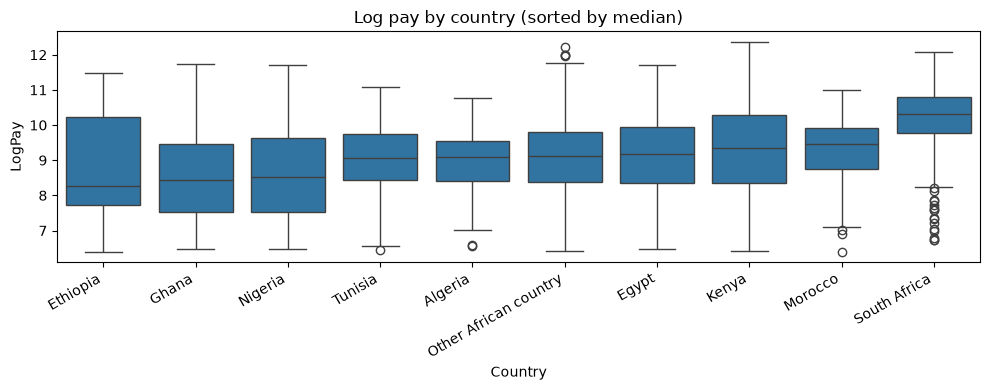

In [6]:
order = df.groupby("Country")["AnnualPayUSD"].median().sort_values().index
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="Country", y="LogPay", order=order)
plt.xticks(rotation=30, ha="right")
plt.title("Log pay by country (sorted by median)")
plt.tight_layout()
plt.show()

What it shows: Country differences outweigh any individual numerical feature. The median jumps from roughly USD 4k in Ethiopia and USD 5k in Nigeria to roughly USD 30k in South Africa, a seven-fold difference.

Decision: I keep Country and one-hot encode it, since it has no natural order. During data cleaning, countries with fewer than 30 respondents were grouped into “Other African country”, so each category has enough rows for the model to learn from. This indicates that tree-based models should work well as they can learn country-specific effects.

## 4. Feature engineering and preprocessing

### 4.1. Feature selection and train/test split

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

NUMERIC = ["YearsCode", "WorkExp", "OnlineCourses", "SurveyYear"]
CATEGORICAL = ["Country", "AgeGroup", "Education", "WorkMode", "OrgSize", "EmploymentType", "RoleGroup"]
FEATURES = NUMERIC + CATEGORICAL

X = df[FEATURES]
y = np.log1p(df["AnnualPayUSD"])          # model target: log(1 + annual pay)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1084, 11) | Test: (271, 11)


### 4.2. Scaling and encoding

In [8]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
X_train_prep = preprocessor.fit_transform(X_train)   # learns means/std and categories from TRAIN only
X_test_prep = preprocessor.transform(X_test)         # applies the same transformation to TEST
feature_names = preprocessor.get_feature_names_out()
print("Columns after encoding:", X_train_prep.shape[1])
print("Train numeric means (should be ~0):", X_train_prep[:, :4].mean(axis=0).round(3))
print("Test numeric means (close to 0, not exact):", X_test_prep[:, :4].mean(axis=0).round(3))

Columns after encoding: 40
Train numeric means (should be ~0): [-0.  0. -0. -0.]
Test numeric means (close to 0, not exact): [ 0.041  0.006 -0.048  0.049]


I dropped ResponseId, CompTotal, Currency and the free-text columns because they’re IDs, leak the target or can’t be used as app inputs. The strongest predictors so far are Country, YearsCode (0.42) and WorkExp (0.39). The data is split 80/20 (1,084 train, 271 test), categories are one-hot encoded (11 inputs become 40 columns), and numeric features are scaled using the training set only. That’s why the training means are exactly 0 and the test means are only close to 0.

## 5. Model training and comparison

### 5.1. Tuning SGDRegressor

In [9]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

X_tr, X_val, y_tr, y_val = train_test_split(X_train_prep, y_train, test_size=0.2, random_state=42)

results = []
for eta0 in [0.001, 0.01, 0.05]:                        # learning rate
    for alpha in [0.0001, 0.001, 0.01, 0.1, 0.3, 1.0]:  
        for epochs in [50, 100, 200]:
            sgd = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, random_state=42)
            for _ in range(epochs):
                sgd.partial_fit(X_tr, y_tr)
            results.append({"eta0": eta0, "alpha": alpha, "epochs": epochs,
                            "val_MSE": mean_squared_error(y_val, sgd.predict(X_val))})

tuning = pd.DataFrame(results).sort_values("val_MSE").reset_index(drop=True)
best = tuning.iloc[0]
print("Best:", best.round(4).to_dict())
tuning.head(10).round(4)

Best: {'eta0': 0.001, 'alpha': 0.1, 'epochs': 200.0, 'val_MSE': 1.1672}


,eta0,alpha,epochs,val_MSE
0,0.001,0.10,200,1.1672
1,0.001,0.10,100,1.1741
2,0.010,0.10,200,1.1816
3,0.010,0.10,100,1.1816
4,0.010,0.10,50,1.1816
5,0.010,0.01,200,1.1983
6,0.001,0.30,200,1.1990
7,0.001,0.30,100,1.1991
8,0.010,0.01,100,1.1992
9,0.010,0.01,50,1.2027


The best settings were a learning rate of 0.001, alpha of 0.1 and 200 epochs and validation MSE of 1.1672. Larger learning rates and very weak or very strong regularisation all made the loss worse.

### 5.2. SGDRegressor loss curve

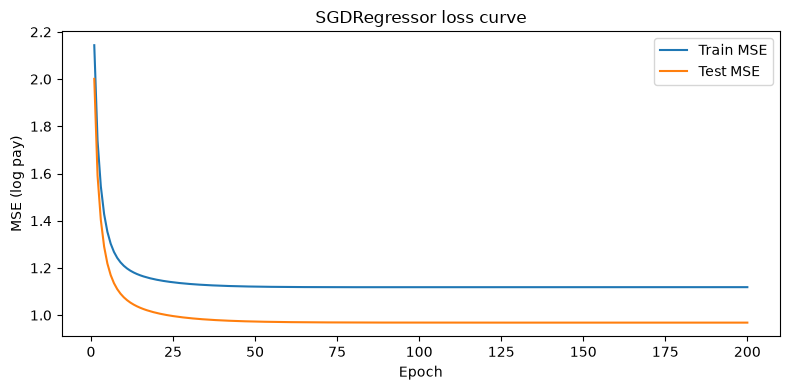

Final train MSE: 1.1186 | Final test MSE: 0.9684


In [10]:
EPOCHS = int(best["epochs"])
sgd = SGDRegressor(learning_rate="constant", eta0=best["eta0"], alpha=best["alpha"], random_state=42)

train_loss, test_loss = [], []
for epoch in range(EPOCHS):
    sgd.partial_fit(X_train_prep, y_train)          
    train_loss.append(mean_squared_error(y_train, sgd.predict(X_train_prep)))
    test_loss.append(mean_squared_error(y_test, sgd.predict(X_test_prep)))

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_loss, label="Train MSE")
plt.plot(range(1, EPOCHS + 1), test_loss, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (log pay)")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Final train MSE: {train_loss[-1]:.4f} | Final test MSE: {test_loss[-1]:.4f}")

Both losses drop fast and level off by about epoch 50 (train 1.1186, test 0.9684), and the test loss never rises, so the model is not over-fitting.

### 5.3. Other models and the comparison table

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

depth_mse = {d: mean_squared_error(y_val, DecisionTreeRegressor(max_depth=d, random_state=42)
                                   .fit(X_tr, y_tr).predict(X_val))
             for d in [3, 4, 5, 6, 8, 10, None]}
leaf_mse = {l: mean_squared_error(y_val, RandomForestRegressor(n_estimators=300, min_samples_leaf=l,
                                  random_state=42, n_jobs=-1).fit(X_tr, y_tr).predict(X_val))
            for l in [1, 3, 5, 10]}
best_depth, best_leaf = min(depth_mse, key=depth_mse.get), min(leaf_mse, key=leaf_mse.get)
print("Best tree depth:", best_depth, "| Best forest min_samples_leaf:", best_leaf)

models = {
    "SGDRegressor (gradient descent)": sgd,
    "LinearRegression (closed form)": LinearRegression().fit(X_train_prep, y_train),
    "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=best_depth, random_state=42).fit(X_train_prep, y_train),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=300, min_samples_leaf=best_leaf,
                                                   random_state=42, n_jobs=-1).fit(X_train_prep, y_train),
}

comparison = pd.DataFrame([
    {"Model": name,
     "Train MSE": mean_squared_error(y_train, m.predict(X_train_prep)),
     "Test MSE": mean_squared_error(y_test, m.predict(X_test_prep))}
    for name, m in models.items()
]).sort_values("Test MSE").reset_index(drop=True)
comparison.round(4)

Best tree depth: 6 | Best forest min_samples_leaf: 10


,Model,Train MSE,Test MSE
0,SGDRegressor (gradient descent),1.1186,0.9684
1,LinearRegression (closed form),1.0541,0.9717
2,RandomForestRegressor,0.8875,0.9963
3,DecisionTreeRegressor,0.9568,1.2832


The best model is SGDRegressor simply because it has the lowest test MSE of 0.9684.

### 5.4. Feature importance

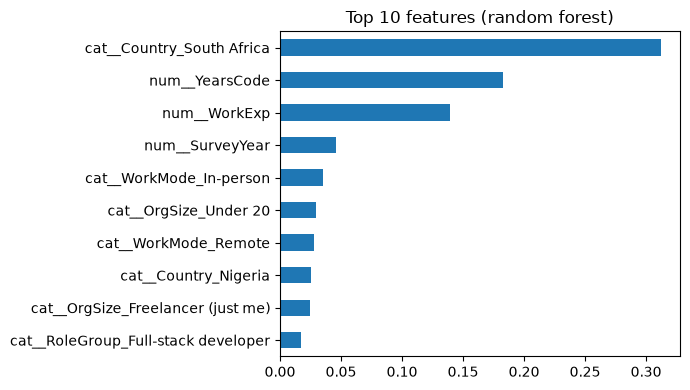

In [12]:
importance = pd.Series(models["RandomForestRegressor"].feature_importances_, index=feature_names)
importance.sort_values(ascending=False).head(10).plot.barh(figsize=(7, 4), title="Top 10 features (random forest)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Being in South Africa (0.31), years of coding (0.18) and work experience (0.14) matter most for pay, which essentially matches what the EDA showed.

## 6. Best-fit line, saving the model and prediction

### 6.1. Scatter plot before and after

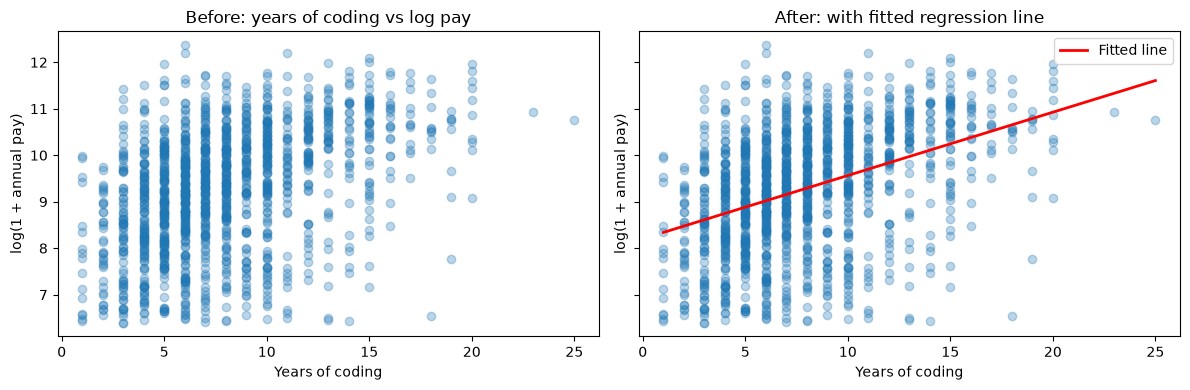

Slope: 0.1362 | Intercept: 8.2022


In [13]:
top = "YearsCode"  

line = LinearRegression().fit(X_train[[top]], y_train)
xs = pd.DataFrame({top: np.linspace(df[top].min(), df[top].max(), 100)})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax in axes:
    ax.scatter(df[top], df["LogPay"], alpha=0.3)
    ax.set(xlabel="Years of coding", ylabel="log(1 + annual pay)")
axes[0].set_title("Before: years of coding vs log pay")
axes[1].plot(xs[top], line.predict(xs), color="red", linewidth=2, label="Fitted line")
axes[1].set_title("After: with fitted regression line")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Slope: {line.coef_[0]:.4f} | Intercept: {line.intercept_:.4f}")

The slope of 0.1362 means roughly +15% pay per extra year of coding.

### 6.2. Save the best model with its preprocessing

In [14]:
import joblib
from pathlib import Path
from sklearn.pipeline import Pipeline

api_dir = Path("../API")
api_dir.mkdir(exist_ok=True)        

best_pipeline = Pipeline([("preprocessor", preprocessor), ("model", sgd)])
joblib.dump(best_pipeline, api_dir / "best_model.pkl")
print("Saved", (api_dir / "best_model.pkl").resolve())

Saved /home/nakuwa/Desktop/Software/Trimester 6/linear_regression_model/summative/API/best_model.pkl


The model is saved as a Pipeline with the scaler and encoder, so the API can take raw inputs.

### 6.3. Predict one row of the test set

In [15]:
def predict_pay(row, model_path="../API/best_model.pkl"):
    """Load the saved pipeline and return predicted annual pay in USD for one row."""
    model = joblib.load(model_path)
    log_pay = model.predict(row)[0]
    return float(np.expm1(log_pay))   

row = X_test.iloc[[0]]               
print(row.to_dict("records")[0])
print(f"Predicted pay: ${predict_pay(row):,.0f}")
print(f"Actual pay:    ${np.expm1(y_test.iloc[0]):,.0f}")

{'YearsCode': 4.0, 'WorkExp': 4.0, 'OnlineCourses': 1, 'SurveyYear': 2023, 'Country': 'South Africa', 'AgeGroup': '18-24', 'Education': 'Secondary or less', 'WorkMode': 'Hybrid', 'OrgSize': '100-499', 'EmploymentType': 'Employed', 'RoleGroup': 'Full-stack developer'}
Predicted pay: $11,366
Actual pay:    $25,936


The prediction of USD 11,366 against an actual USD 25,936 basically matches the model’s typical error.